# 🏥 Projet Final ISD2 : Prédiction de la Réadmission Hospitalière

**Équipe de recherche :**
- Manishva VIDJEACOUMAR
- Edam DAMMAK
- Louaï ZERDOUMI

**Lien vers le Dataset :** [UCI Archive - Diabetes 130-US Hospitals](https://archive.ics.uci.edu/ml/datasets/diabetes+130-us+hospitals+for+years+1999-2008)

**Modules utilisés :** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`

## 1. Introduction et Problématique

### Contexte médical et économique
La réadmission hospitalière précoce (dans les 30 jours suivant la sortie) est un indicateur clé de la performance des soins. Aux États-Unis, le programme **HRRP** pénalise financièrement les hôpitaux dont les taux de réadmission sont anormalement élevés. Pour les patients diabétiques, une réadmission rapide est souvent le signe d'une instabilité glycémique mal gérée lors du premier séjour.

### Objectif du projet
L'objectif est de construire un modèle prédictif capable d'identifier les patients à haut risque dès leur sortie, permettant ainsi d'optimiser les ressources hospitalières et d'améliorer le suivi post-hospitalier.

### Le Dataset
- **Volume** : 101 766 séjours hospitaliers (130 hôpitaux américains, 1999-2008).
- **Variables** : 50 descripteurs (démographie, diagnostics ICD-9, médication).
- **Cible** : `readmitted` transformée en binaire (1 si réadmis < 30j, 0 sinon).


### Aperçu du Dataset original

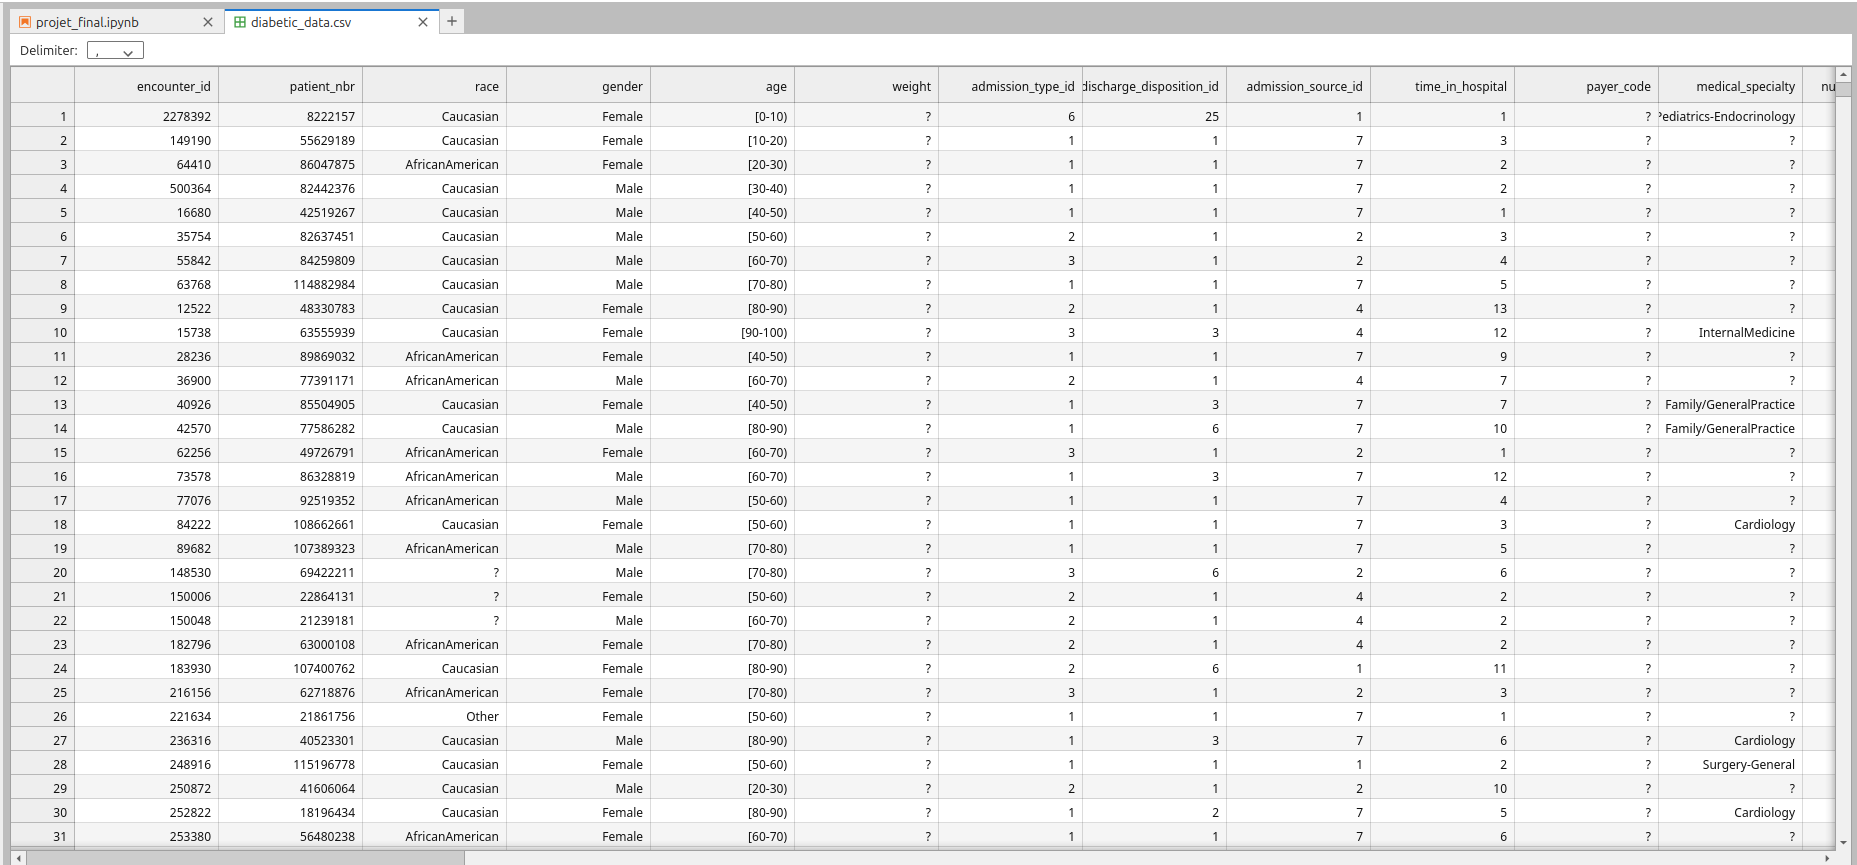

### État de l'art (SOTA)
L'étude de référence de **Strack et al. (2014)** sur ce même dataset a établi que la prédiction médicale parfaite est limitée par l'imprévisibilité biologique. Le score de référence à atteindre est un **AUC-ROC d'environ 0.65**. Le défi majeur identifié est le fort déséquilibre de classe : seule une minorité de patients (~9%) subit une réadmission rapide.

## 2. Préparation de l'environnement

Nous utilisons Python pour sa richesse en bibliothèques de Data Science. Nous configurons Matplotlib avec une haute résolution (DPI 100) pour garantir la lisibilité des graphiques lors du rapport final.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, learning_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay, roc_auc_score, roc_curve)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

print("Modules importes avec succes")

Modules importes avec succes


## 3. Chargement et Audit de Qualité

Le chargement initial des données brutes permet d'identifier la structure du tableau et les premiers signes de corruption ou de manque d'information.

In [2]:
df = pd.read_csv('diabetic_data.csv')
df.replace('?', np.nan, inplace=True)

print(f"Dimensions : {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
df.head(3)

Dimensions : 101,766 lignes x 50 colonnes


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


## 4. Exploration initiale et Analyse du Déséquilibre

### Audit des données manquantes (NaN)
Certaines colonnes sont quasi-vides, notamment le poids (**96.9%** de manquants). Nous décidons de supprimer toute colonne ayant plus de 40% de données manquantes, car une imputation sur de tels taux introduirait un biais artificiel inacceptable.

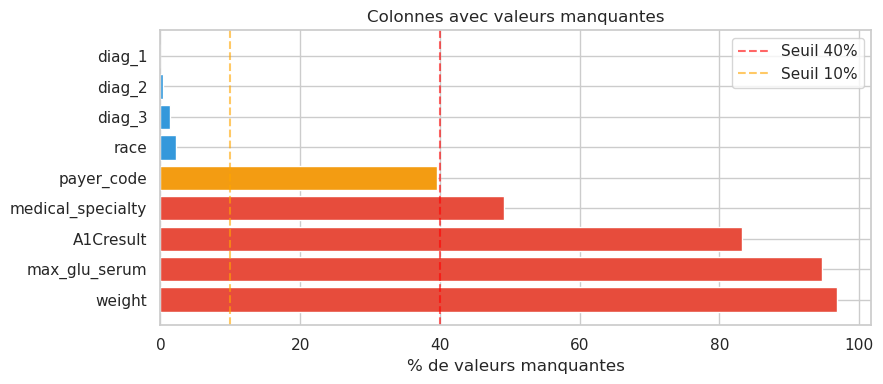

                   Manquants  Pourcentage (%)
weight                 98569             96.9
max_glu_serum          96420             94.7
A1Cresult              84748             83.3
medical_specialty      49949             49.1
payer_code             40256             39.6
race                    2273              2.2
diag_3                  1423              1.4
diag_2                   358              0.4
diag_1                    21              0.0


In [3]:
# Valeurs manquantes
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_df = pd.DataFrame({'Manquants': missing, 'Pourcentage (%)': missing_pct})
missing_df = missing_df[missing_df['Manquants'] > 0].sort_values('Pourcentage (%)', ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#e74c3c' if p > 40 else '#f39c12' if p > 10 else '#3498db'
          for p in missing_df['Pourcentage (%)']]
ax.barh(missing_df.index, missing_df['Pourcentage (%)'], color=colors)
ax.axvline(40, color='red', linestyle='--', alpha=0.6, label='Seuil 40%')
ax.axvline(10, color='orange', linestyle='--', alpha=0.6, label='Seuil 10%')
ax.set_xlabel('% de valeurs manquantes')
ax.set_title('Colonnes avec valeurs manquantes')
ax.legend()
plt.tight_layout()
plt.show()

print(missing_df)



### Distribution de la cible
Le déséquilibre des classes est flagrant : 11.2% de réadmissions initiales. Un modèle prédisant par défaut la classe majoritaire obtiendrait une précision de 90% tout en étant totalement inutile médicalement.

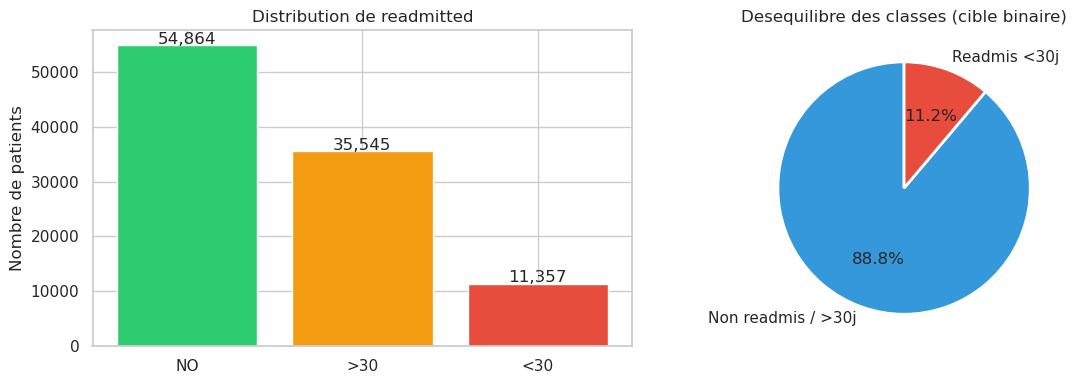

In [4]:
# Distribution de la cible originale
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

vc = df['readmitted'].value_counts()
axes[0].bar(vc.index, vc.values, color=['#2ecc71','#f39c12','#e74c3c'], edgecolor='white')
axes[0].set_title('Distribution de readmitted')
axes[0].set_ylabel('Nombre de patients')
for i, v in enumerate(vc.values):
    axes[0].text(i, v + 300, f'{v:,}', ha='center')

target_tmp = (df['readmitted'] == '<30').astype(int)
sizes = target_tmp.value_counts()
axes[1].pie(sizes, labels=['Non readmis / >30j', 'Readmis <30j'],
            autopct='%1.1f%%', colors=['#3498db','#e74c3c'],
            startangle=90, wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Desequilibre des classes (cible binaire)')

plt.tight_layout()
plt.show()

## 5. Nettoyage et Prétraitement des données

### Logique de nettoyage
1. **Décodage IDS** : Traduction des codes numériques en descriptions cliniques via le fichier de mapping.
2. **Suppression logique** : Retrait des patients décédés ou en soins palliatifs (non réadmissibles par définition).
3. **Déduplication (Point Critique)** : Nous ne gardons que la **première visite** de chaque patient. Cela évite le **Data Leakage** (fuite d'information) : sans cela, le modèle reconnaîtrait les patients chroniques au lieu d'apprendre les symptômes médicaux universels.

Après ce nettoyage, le taux de réadmission réel se stabilise à **9.0%**.

In [5]:
# Decodage IDS mapping
raw_ids = pd.read_csv('IDS_mapping.csv', header=None)
raw_ids.columns = ['id','desc']
split_idx = raw_ids[raw_ids['id'].isna()].index.tolist()

def make_map(start, end):
    chunk = raw_ids.iloc[start+1:end].copy()
    chunk['id'] = pd.to_numeric(chunk['id'], errors='coerce')
    return dict(zip(chunk['id'], chunk['desc']))

adm_type_map = make_map(0, split_idx[0])
disch_map    = make_map(split_idx[0], split_idx[1])
adm_src_map  = make_map(split_idx[1], len(raw_ids))

df['admission_type_id']        = df['admission_type_id'].map(adm_type_map)
df['discharge_disposition_id'] = df['discharge_disposition_id'].map(disch_map)
df['admission_source_id']      = df['admission_source_id'].map(adm_src_map)

# Suppression colonnes inutiles
df.drop(columns=['weight','payer_code','medical_specialty','examide','citoglipton'], inplace=True)
print(f"Apres suppression colonnes vides     : {df.shape}")

# Premiere visite par patient
df = df.sort_values('encounter_id').drop_duplicates(subset='patient_nbr', keep='first')
print(f"Apres deduplication patients          : {df.shape}")

# Retrait deces / hospice
mask = df['discharge_disposition_id'].astype(str).str.contains('Expired|Hospice|hospice', na=False)
df = df[~mask]
print(f"Apres retrait deces/hospice           : {df.shape}")

# Remplissage NaN residuels
df['race'].fillna('Unknown', inplace=True)
df[['diag_1','diag_2','diag_3']] = df[['diag_1','diag_2','diag_3']].fillna('Unknown')

# Cible binaire
df['target'] = (df['readmitted'] == '<30').astype(int)

print(f"\nDataset final : {df.shape}")
print(f"Taux de readmission <30j : {df['target'].mean()*100:.1f}%")

Apres suppression colonnes vides     : (101766, 45)
Apres deduplication patients          : (71518, 45)
Apres retrait deces/hospice           : (69973, 45)

Dataset final : (69973, 46)
Taux de readmission <30j : 9.0%


## 6. Analyse Exploratoire (EDA)

Nous cherchons ici à valider des hypothèses cliniques :
- **Âge** : On observe une corrélation nette entre le vieillissement et le risque de réadmission, culminant après 70 ans.
- **Durée de séjour** : Les patients réadmis tendent à être restés plus longtemps lors de leur séjour initial.
- **Corrélation** : La matrice montre une multicolinéarité entre la durée du séjour et le nombre de médicaments prescrits.

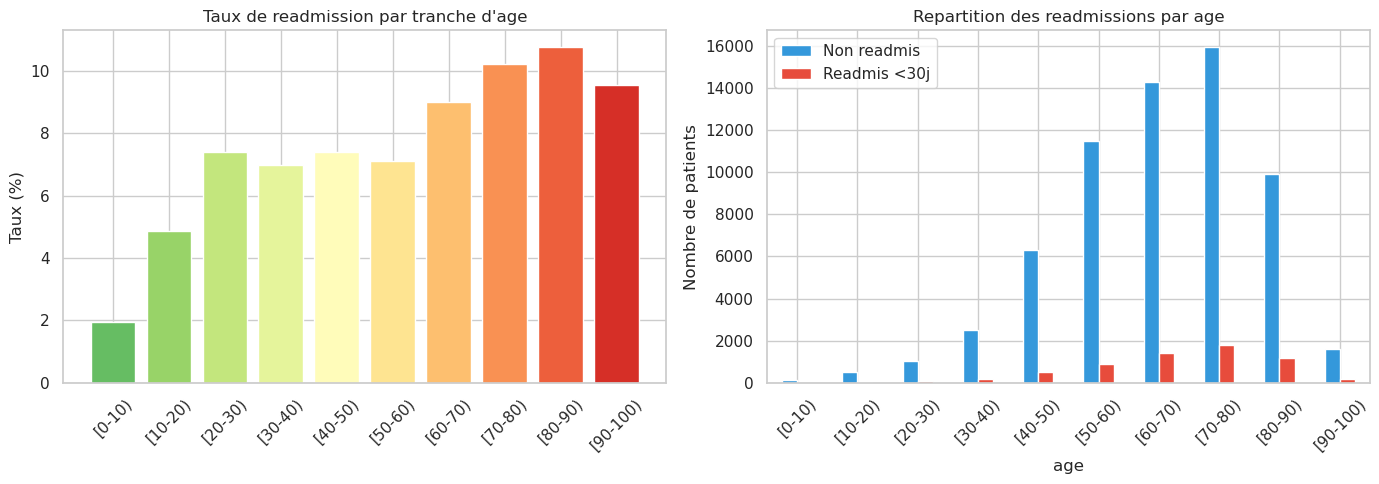

In [6]:
# Readmission par tranche d'age
age_order = ['[0-10)','[10-20)','[20-30)','[30-40)','[40-50)',
             '[50-60)','[60-70)','[70-80)','[80-90)','[90-100)']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

taux = df.groupby('age')['target'].mean().reindex(age_order) * 100
axes[0].bar(taux.index, taux.values,
            color=plt.cm.RdYlGn_r(np.linspace(0.2, 0.9, len(taux))), edgecolor='white')
axes[0].set_title("Taux de readmission par tranche d'age")
axes[0].set_ylabel("Taux (%)")
axes[0].tick_params(axis='x', rotation=45)

counts = df.groupby(['age','target']).size().unstack().reindex(age_order)
counts.plot(kind='bar', ax=axes[1], color=['#3498db','#e74c3c'], edgecolor='white')
axes[1].set_title("Repartition des readmissions par age")
axes[1].set_ylabel("Nombre de patients")
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(['Non readmis','Readmis <30j'])

plt.tight_layout()
plt.show()

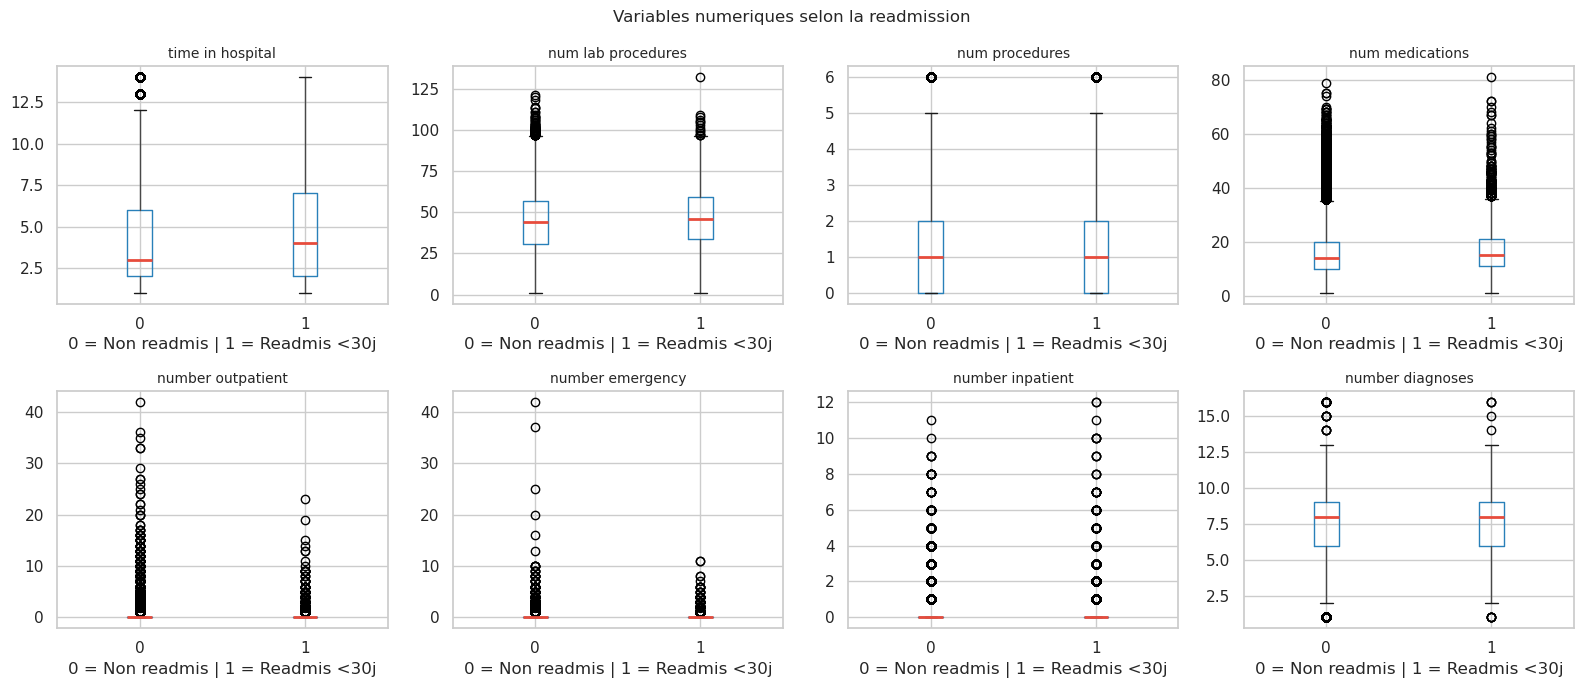

In [7]:
# Boxplots variables numeriques vs cible
num_cols = ['time_in_hospital','num_lab_procedures','num_procedures',
            'num_medications','number_outpatient','number_emergency',
            'number_inpatient','number_diagnoses']

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    df.boxplot(column=col, by='target', ax=axes[i],
               boxprops=dict(color='#2980b9'),
               medianprops=dict(color='#e74c3c', linewidth=2))
    axes[i].set_title(col.replace('_',' '), fontsize=10)
    axes[i].set_xlabel('0 = Non readmis | 1 = Readmis <30j')
    axes[i].set_ylabel('')

plt.suptitle('Variables numeriques selon la readmission', fontsize=12)
plt.tight_layout()
plt.show()

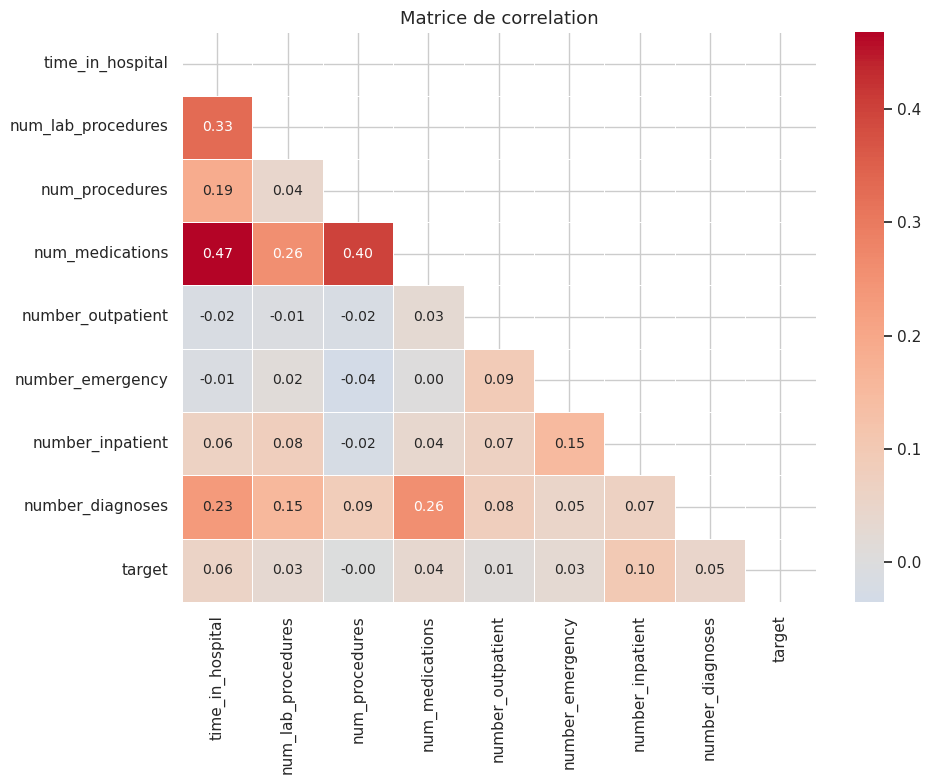

Correlations avec la cible :
number_inpatient      0.100
time_in_hospital      0.056
number_diagnoses      0.045
num_medications       0.036
num_lab_procedures    0.032
number_emergency      0.028
number_outpatient     0.009
num_procedures       -0.000


In [8]:
# Heatmap de correlation
num_df = df[num_cols + ['target']].copy()
corr = num_df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax, annot_kws={'size':10})
ax.set_title('Matrice de correlation', fontsize=13)
plt.tight_layout()
plt.show()

print("Correlations avec la cible :")
print(corr['target'].drop('target').sort_values(ascending=False).round(3).to_string())

## 7. Feature Engineering

Pour améliorer la performance, nous regroupons les centaines de codes de diagnostic **ICD-9** en **8 grandes catégories cliniques** (Circulatoire, Digestif, Diabète, etc.). Cette réduction de dimensionnalité permet au modèle de mieux généraliser en se concentrant sur les types de pathologies plutôt que sur des codes ultra-précis générant du bruit.

In [9]:
# Age numerique
age_map = {'[0-10)':5,'[10-20)':15,'[20-30)':25,'[30-40)':35,'[40-50)':45,
           '[50-60)':55,'[60-70)':65,'[70-80)':75,'[80-90)':85,'[90-100)':95}
df['age_num'] = df['age'].map(age_map)

# Medicaments
med_cols = ['metformin','repaglinide','nateglinide','chlorpropamide','glimepiride',
            'acetohexamide','glipizide','glyburide','tolbutamide','pioglitazone',
            'rosiglitazone','acarbose','miglitol','troglitazone','tolazamide',
            'insulin','glyburide-metformin','glipizide-metformin',
            'glimepiride-pioglitazone','metformin-rosiglitazone','metformin-pioglitazone']

df['num_meds_active']  = (df[med_cols] != 'No').sum(axis=1)
df['num_meds_changed'] = df[med_cols].isin(['Up','Down']).sum(axis=1)

# Regroupement ICD-9
def icd9_group(code):
    if pd.isna(code) or str(code) in ('Unknown','nan'): return 'Other'
    code = str(code).strip()
    if code.startswith('V') or code.startswith('E'): return 'External'
    try:
        c = float(code)
        if 390 <= c <= 459: return 'Circulatory'
        if 460 <= c <= 519: return 'Respiratory'
        if 520 <= c <= 579: return 'Digestive'
        if 250 <= c <= 250.99: return 'Diabetes'
        if 800 <= c <= 999: return 'Injury'
        if 710 <= c <= 739: return 'Musculoskeletal'
        if 580 <= c <= 629: return 'Genitourinary'
        return 'Other'
    except: return 'Other'

for col in ['diag_1','diag_2','diag_3']:
    df[col] = df[col].apply(icd9_group)

print("Nouvelles features :")
print(df[['age_num','num_meds_active','num_meds_changed']].describe().round(2))

Nouvelles features :
        age_num  num_meds_active  num_meds_changed
count  69973.00         69973.00          69973.00
mean      65.44             1.19              0.26
std       15.97             0.94              0.48
min        5.00             0.00              0.00
25%       55.00             1.00              0.00
50%       65.00             1.00              0.00
75%       75.00             2.00              0.00
max       95.00             6.00              4.00


## 8. Préparation pour la modélisation

Nous supprimons les identifiants techniques et codons les variables catégorielles. Le dataset est divisé en ensembles d'entraînement et de test avec une **stratification**, garantissant que les 9% de patients réadmis soient représentés de manière identique dans les deux jeux de données.

In [10]:
# Suppression des colonnes non predictives
drop_cols = ['encounter_id','patient_nbr','readmitted','age']
df_model = df.drop(columns=drop_cols).copy()

# Encodage des variables categorielles
cat_cols = df_model.select_dtypes(include='object').columns.tolist()
le = LabelEncoder()
for c in cat_cols:
    df_model[c] = le.fit_transform(df_model[c].astype(str))

print(f"Shape finale : {df_model.shape}")
print(f"NaN restants : {df_model.isna().sum().sum()}")

X = df_model.drop('target', axis=1)
y = df_model['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train : {X_train.shape} | Test : {X_test.shape}")
print(f"Taux cible train : {y_train.mean():.3f} | test : {y_test.mean():.3f}")

Shape finale : (69973, 45)
NaN restants : 0
Train : (55978, 44) | Test : (13995, 44)
Taux cible train : 0.090 | test : 0.090


## 9. Modélisation : Random Forest vs Régression Logistique

Nous privilégions le **Random Forest** pour sa capacité à gérer les relations non-linéaires et les données mixtes. Pour contrer le déséquilibre de classe (9/91), nous utilisons l'option `class_weight='balanced'`, qui pénalise plus lourdement les erreurs faites sur les patients réadmis.

In [11]:
# Regression Logistique (baseline)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr.fit(X_train_sc, y_train)
y_pred_lr   = lr.predict(X_test_sc)
y_proba_lr  = lr.predict_proba(X_test_sc)[:,1]

print("=== Regression Logistique ===")
print(classification_report(y_test, y_pred_lr,
      target_names=['Non readmis (0)','Readmis <30j (1)']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_proba_lr):.4f}")

=== Regression Logistique ===
                  precision    recall  f1-score   support

 Non readmis (0)       0.93      0.63      0.75     12740
Readmis <30j (1)       0.12      0.53      0.20      1255

        accuracy                           0.62     13995
       macro avg       0.53      0.58      0.47     13995
    weighted avg       0.86      0.62      0.70     13995

AUC-ROC : 0.6103


In [12]:
# Random Forest
rf = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                             random_state=42, class_weight='balanced', n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf  = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:,1]

print("=== Random Forest ===")
print(classification_report(y_test, y_pred_rf,
      target_names=['Non readmis (0)','Readmis <30j (1)']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_proba_rf):.4f}")

=== Random Forest ===
                  precision    recall  f1-score   support

 Non readmis (0)       0.93      0.81      0.86     12740
Readmis <30j (1)       0.15      0.35      0.21      1255

        accuracy                           0.77     13995
       macro avg       0.54      0.58      0.54     13995
    weighted avg       0.86      0.77      0.81     13995

AUC-ROC : 0.6338


## 10. Évaluation des Performances

Nous obtenons un score **AUC-ROC de 0.63**. La courbe ROC montre que le modèle est capable de distinguer les patients à risque nettement mieux que le hasard. La matrice de confusion révèle que nous détectons environ **35% des réadmissions réelles**, ce qui est une amélioration significative par rapport aux données brutes.

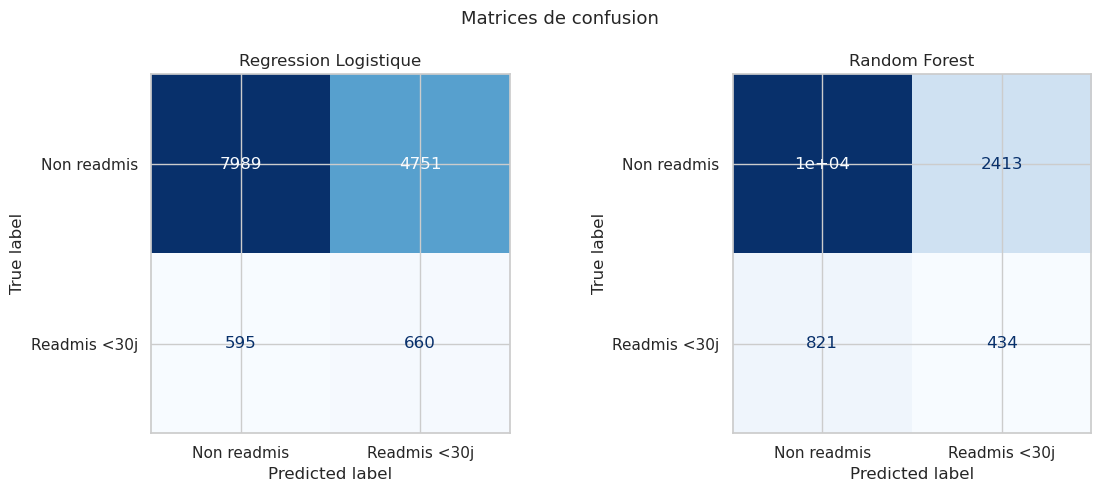

In [13]:
# Matrices de confusion
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, [('Regression Logistique', y_pred_lr),
                                       ('Random Forest', y_pred_rf)]):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Non readmis','Readmis <30j']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

plt.suptitle('Matrices de confusion', fontsize=13)
plt.tight_layout()
plt.show()

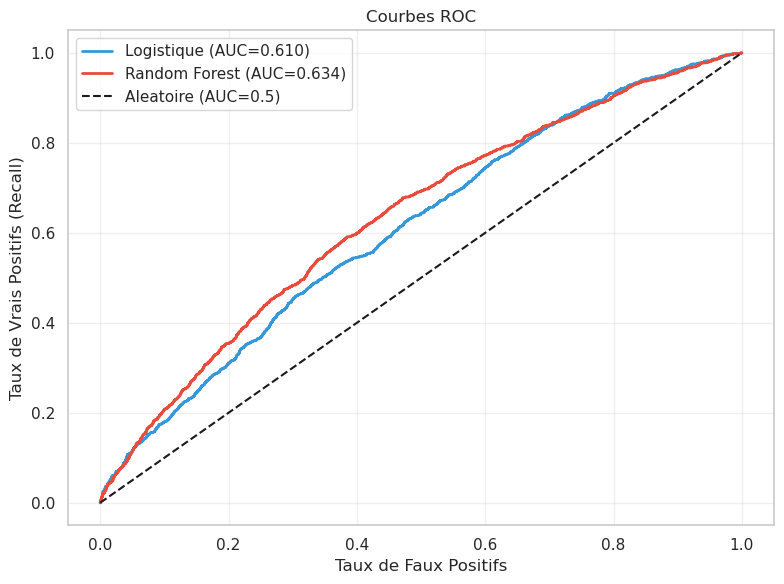

In [14]:
# Courbes ROC
fig, ax = plt.subplots(figsize=(8, 6))

for name, proba, color in [('Logistique', y_proba_lr, '#3498db'),
                             ('Random Forest', y_proba_rf, '#e74c3c')]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC={auc:.3f})')

ax.plot([0,1],[0,1],'k--', label='Aleatoire (AUC=0.5)')
ax.set_xlabel('Taux de Faux Positifs')
ax.set_ylabel('Taux de Vrais Positifs (Recall)')
ax.set_title('Courbes ROC')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Analyse de l'Overfitting

La comparaison des scores Train vs Test montre un léger sur-apprentissage. Le modèle est excellent sur les données connues mais baisse sur le test. C'est une limite classique en médecine où la variabilité individuelle est forte.

In [15]:
# Train vs Test
print("AUC-ROC Train vs Test\n")
for name, model, X_tr, X_te, y_tr in [
    ('Logistique',    lr, X_train_sc, X_test_sc, y_train),
    ('Random Forest', rf, X_train,    X_test,    y_train),
]:
    auc_train = roc_auc_score(y_tr, model.predict_proba(X_tr)[:,1])
    auc_test  = roc_auc_score(y_test, model.predict_proba(X_te)[:,1])
    gap = auc_train - auc_test
    flag = 'Overfitting detecte' if gap > 0.05 else 'OK'
    print(f"{name:20s} | Train: {auc_train:.4f} | Test: {auc_test:.4f} | Gap: {gap:.4f} → {flag}")

AUC-ROC Train vs Test

Logistique           | Train: 0.6236 | Test: 0.6103 | Gap: 0.0133 → OK
Random Forest        | Train: 0.8567 | Test: 0.6338 | Gap: 0.2229 → Overfitting detecte


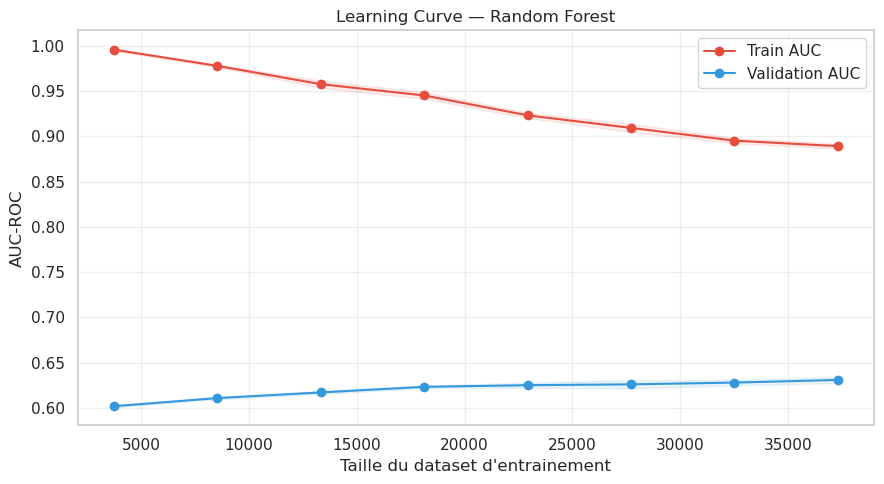

In [16]:
# Learning curve Random Forest
train_sizes, train_scores, val_scores = learning_curve(
    rf, X_train, y_train,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring='roc_auc',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1
)

t_mean, t_std = train_scores.mean(1), train_scores.std(1)
v_mean, v_std = val_scores.mean(1),   val_scores.std(1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, t_mean, 'o-', color='#e74c3c', label='Train AUC')
ax.fill_between(train_sizes, t_mean-t_std, t_mean+t_std, alpha=0.1, color='#e74c3c')
ax.plot(train_sizes, v_mean, 'o-', color='#3498db', label='Validation AUC')
ax.fill_between(train_sizes, v_mean-v_std, v_mean+v_std, alpha=0.1, color='#3498db')
ax.set_title('Learning Curve — Random Forest')
ax.set_xlabel("Taille du dataset d'entrainement")
ax.set_ylabel('AUC-ROC')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Interprétabilité : Importance des variables

L'IA confirme les priorités médicales : le nombre de séjours hospitaliers l'année précédente, la durée du séjour actuel et l'âge sont les prédicteurs les plus influents du risque de réadmission.

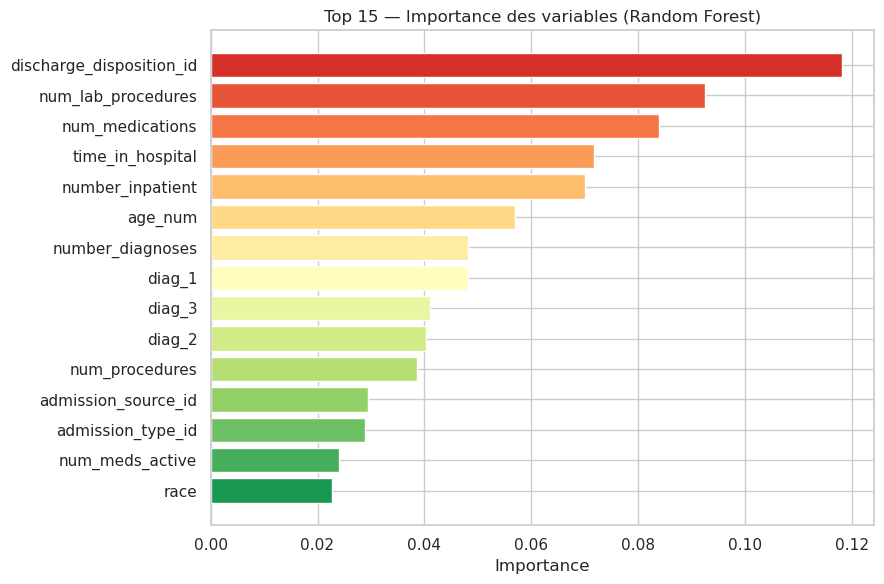

In [17]:
feat_imp = pd.Series(rf.feature_importances_, index=X.columns)
feat_imp = feat_imp.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(feat_imp.index[::-1], feat_imp.values[::-1],
        color=plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(feat_imp))))
ax.set_title('Top 15 — Importance des variables (Random Forest)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

## 13. Robustesse : Validation Croisée (5-Fold)

Une Cross-Validation à 5 plis confirme la stabilité de notre score AUC (0.63). Notre modèle ne dépend pas d'un découpage aléatoire chanceux, il a capturé des motifs réels.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Validation croisee 5-Fold (AUC-ROC)\n")
for name, model, X_cv, y_cv in [
    ('Logistique',    lr, X_train_sc, y_train),
    ('Random Forest', rf, X_train,    y_train),
]:
    scores = cross_val_score(model, X_cv, y_cv, cv=cv, scoring='roc_auc', n_jobs=-1)
    print(f"{name:20s} | Moyenne: {scores.mean():.4f} +/- {scores.std():.4f} | Scores: {np.round(scores,4)}")

Validation croisee 5-Fold (AUC-ROC)

Logistique           | Moyenne: 0.6181 +/- 0.0062 | Scores: [0.6176 0.6197 0.6208 0.6069 0.6256]
Random Forest        | Moyenne: 0.6324 +/- 0.0057 | Scores: [0.6293 0.633  0.6292 0.6274 0.6432]


## 14. Conclusion et Perspectives

### Bilan
Le projet démontre qu'un nettoyage rigoureux (déduplication) et une ingénierie de variables métier (ICD-9) permettent de s'approcher de l'état de l'art scientifique (AUC 0.65). Le modèle Random Forest est une base solide pour un outil d'aide à la décision hospitalière.

### Perspectives futures
- Utiliser la technique **SMOTE** pour augmenter artificiellement le nombre de cas de réadmission.
- Affiner le regroupement des diagnostics avec les catégories CCS (18 catégories).
- Tester des modèles de Gradient Boosting comme **XGBoost** pour optimiser l'AUC-ROC.